# 05 · Diffusion augmentation of a rare malignant class (`akiec`)

**Hypothesis.** The malignant sub-classifier struggles most on `akiec`
(actinic keratosis / intraepithelial carcinoma, ~327 images). If we train a
small **DDPM** on the `akiec` training images and add synthetic samples, the
sub-classifier's **`akiec` recall / macro-F1** should improve.

**Ablation.** We retrain the malignant multimodal model on
`real malignant train + synthetic akiec` and save it as
`malignant_multimodal_aug.keras`. Notebook 06 compares it head-to-head against
the no-synthetic model on the identical held-out test slice.

**Honesty note.** Generation is at 64×64 (T4 time budget) and bicubically
upscaled to 224; metadata for synthetic images is sampled from the `akiec`
training distribution. Both are disclosed limitations in the report.

---
*Part of: **A Multimodal, Explainable Hierarchical Framework for Skin-Lesion
Classification with Diffusion-Based Augmentation of Rare Malignancies.***
All training/eval logic lives in the tested modules under `src/`; these
notebooks orchestrate them on a Colab T4.

In [ ]:
!pip -q install "diffusers>=0.27,<0.41" accelerate >/dev/null 2>&1
print("diffusers ready")

diffusers ready


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import shutil

DRIVE_PROJECT = '/content/drive/MyDrive/Projects/Skin_Cancer_Research_Grant2024'
#
LOCAL_PROJECT = '/content/Skin_Cancer_Research_Grant2024'

os.makedirs(LOCAL_PROJECT, exist_ok=True)

folders = ['data']

for folder in folders:
    source = os.path.join(DRIVE_PROJECT, folder)
    destination = os.path.join(LOCAL_PROJECT, folder)

    print(f"Copying {folder}...")

    shutil.copytree(
        source,
        destination,
        dirs_exist_ok=True
    )

    print(f"✓ {folder} copied")

print("\nAll folders copied to Colab!")

Copying data...
✓ data copied

All folders copied to Colab!


In [ ]:

import os, sys

try:
    PROJECT_DIR = '/content/drive/MyDrive/Projects/Skin_Cancer_Research_Grant2024'
except Exception:
    # Running locally / not on Colab
    PROJECT_DIR = os.path.abspath('..')

SRC       = os.path.join(PROJECT_DIR, 'src')
MODELS_DIR= os.path.join(PROJECT_DIR, 'models')
DATA_DIR  = '/content/Skin_Cancer_Research_Grant2024/data'
FIG_DIR   = os.path.join(PROJECT_DIR, 'report', 'figures')
SPLIT_CSV = os.path.join(MODELS_DIR, 'ham_split.csv')
PREP_JSON = os.path.join(MODELS_DIR, 'preprocessing.json')
for d in (MODELS_DIR, DATA_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)

assert os.path.isdir(SRC), f"src/ not found at {SRC} — set PROJECT_DIR correctly"
sys.path.insert(0, SRC)
print("PROJECT_DIR =", PROJECT_DIR)

PROJECT_DIR = /content/drive/MyDrive/Projects/Skin_Cancer_Research_Grant2024


## Train a DDPM on the `akiec` training images (time-boxed)

In [ ]:
import os, pandas as pd
import diffusion as dfn

df = pd.read_csv(SPLIT_CSV)
akiec_train = df[(df.dx == 'akiec') & (df.split == 'train')]
paths = akiec_train['image_path'].tolist()
print("akiec training images:", len(paths))

DIFF_DIR = os.path.join(MODELS_DIR, 'diffusion', 'akiec')
dfn.train_ddpm(
    paths, out_dir=DIFF_DIR,
    image_size=64, epochs=300, batch_size=16, lr=1e-4,
    base_channels=128, use_ema=True,
    max_minutes=120,     # hard wall-clock cap for a free T4 session
    log_every=25,
)

akiec training images: 236


Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.
Flax classes are deprecated and will be removed in Diffusers v0.40.0. We recommend migrating to PyTorch classes or pinning your version of Diffusers.


[diffusion] training on 236 images @ 64px, 300 epochs, batch 16, device=cuda
  epoch    0/300  loss=0.3699  (0.2 min)
  epoch   25/300  loss=0.0260  (3.5 min)
  epoch   50/300  loss=0.0188  (7.0 min)
  epoch   75/300  loss=0.0172  (10.5 min)
  epoch  100/300  loss=0.0149  (14.0 min)
  epoch  125/300  loss=0.0092  (17.5 min)
  epoch  150/300  loss=0.0190  (20.9 min)
  epoch  175/300  loss=0.0141  (24.4 min)
  epoch  200/300  loss=0.0177  (27.9 min)
  epoch  225/300  loss=0.0203  (31.4 min)
  epoch  250/300  loss=0.0149  (34.9 min)
  epoch  275/300  loss=0.0201  (38.3 min)
  epoch  299/300  loss=0.0138  (41.7 min)
[diffusion] saved model to /content/drive/MyDrive/Projects/Skin_Cancer_Research_Grant2024/models/diffusion/akiec


'/content/drive/MyDrive/Projects/Skin_Cancer_Research_Grant2024/models/diffusion/akiec'

## Inspect a few samples (sanity check before bulk generation)

[diffusion] generated 8/8


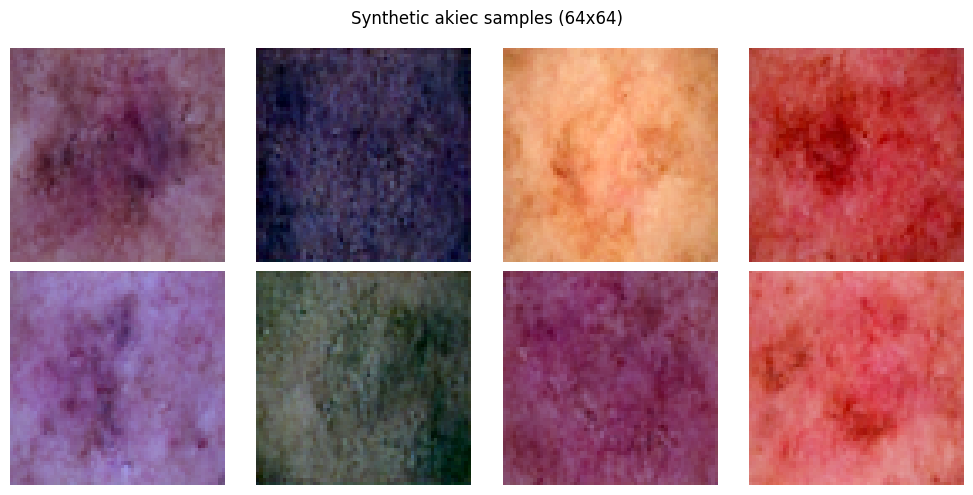

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

preview = dfn.generate_images(DIFF_DIR, n=8, out_dir='/tmp/preview',
                              image_size=64, upscale_to=None,
                              num_inference_steps=1000, seed=7)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for ax, p in zip(axes.ravel(), preview):
    ax.imshow(Image.open(p)); ax.axis('off')
fig.suptitle("Synthetic akiec samples (64x64)")
plt.tight_layout(); plt.show()

## Generate the synthetic set + sample matching metadata

In [ ]:
import numpy as np
N_SYNTH = 400
SYN_DIR = os.path.join(PROJECT_DIR, 'synthetic', 'akiec')
syn_paths = dfn.generate_images(DIFF_DIR, n=N_SYNTH, out_dir=SYN_DIR,
                                image_size=64, upscale_to=224,
                                num_inference_steps=1000, seed=2024)
print("generated", len(syn_paths), "synthetic akiec images ->", SYN_DIR)

# Sample metadata from the akiec TRAIN distribution (disclosed limitation).
r = np.random.RandomState(2024)
ages = akiec_train['age'].dropna().to_numpy()
sexes = akiec_train['sex'].astype(str).to_numpy()
locs = akiec_train['localization'].astype(str).to_numpy()
syn = pd.DataFrame({'image_path': syn_paths})
syn['age'] = r.choice(ages, len(syn)) if len(ages) else 50.0
syn['sex'] = r.choice(sexes, len(syn)) if len(sexes) else 'unknown'
syn['localization'] = r.choice(locs, len(syn)) if len(locs) else 'unknown'
syn['dx'] = 'akiec'
syn['is_synthetic'] = True
syn.head()

[diffusion] generated 64/400
[diffusion] generated 128/400
[diffusion] generated 192/400
[diffusion] generated 256/400
[diffusion] generated 320/400
[diffusion] generated 384/400
[diffusion] generated 400/400
generated 400 synthetic akiec images -> /content/drive/MyDrive/Projects/Skin_Cancer_Research_Grant2024/synthetic/akiec


,image_path,age,sex,localization,dx,is_synthetic
0,/content/drive/MyDrive/Projects/Skin_Cancer_Re...,85.0,male,face,akiec,True
1,/content/drive/MyDrive/Projects/Skin_Cancer_Re...,70.0,female,lower extremity,akiec,True
2,/content/drive/MyDrive/Projects/Skin_Cancer_Re...,75.0,male,face,akiec,True
3,/content/drive/MyDrive/Projects/Skin_Cancer_Re...,60.0,male,upper extremity,akiec,True
4,/content/drive/MyDrive/Projects/Skin_Cancer_Re...,75.0,female,lower extremity,akiec,True


## Retrain the malignant multimodal model **with** synthetic akiec

In [ ]:
import json
import data as D, metadata as M, model as Model

STAGE = 'malignant'
proc = M.MetadataProcessor.load(PREP_JSON)

mal = D.filter_for_stage(df, STAGE)
mal_train = mal[mal.split == 'train'].copy()
mal_val   = mal[mal.split == 'val'].copy()

# Label the synthetic rows for this stage and append to the training rows only.
syn_rows = syn.copy()
syn_rows['label'] = 'akiec'
syn_rows['label_idx'] = D.STAGE_CLASSES[STAGE].index('akiec')
syn_rows['split'] = 'train'
aug_train = pd.concat([mal_train, syn_rows], ignore_index=True)
print("real malignant train:", len(mal_train), "-> augmented:", len(aug_train))

class_weight = D.compute_class_weights(aug_train, STAGE)
tf_tr = D.make_dataset(aug_train, STAGE, proc, multimodal=True, batch_size=32, training=True, augment=True)
tf_va = D.make_dataset(mal_val,  STAGE, proc, multimodal=True, batch_size=32, training=False)

mm_aug = Model.compile_model(Model.build_multimodal_model(len(D.STAGE_CLASSES[STAGE]), proc.feature_dim))
aug_path = os.path.join(MODELS_DIR, 'malignant_multimodal_aug.keras')
hist = mm_aug.fit(tf_tr, validation_data=tf_va, epochs=30,
                  class_weight=class_weight,
                  callbacks=Model.make_callbacks(aug_path))
mm_aug.save(aug_path)
json.dump(hist.history, open(aug_path.replace('.keras', '_history.json'), 'w'))
print("saved diffusion-augmented model ->", aug_path)

real malignant train: 1412 -> augmented: 1812
43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 312s 3s/step - accuracy: 0.5419 - loss: 1.1269 - val_accuracy: 0.5703 - val_loss: 1.1038 - learning_rate: 1.0000e-04
Epoch 2/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 50s 868ms/step - accuracy: 0.6181 - loss: 0.9216 - val_accuracy: 0.5823 - val_loss: 0.9922 - learning_rate: 1.0000e-04
Epoch 3/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 52s 912ms/step - accuracy: 0.6584 - loss: 0.8214 - val_accuracy: 0.5984 - val_loss: 0.9000 - learning_rate: 1.0000e-04
Epoch 4/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 81s 896ms/step - accuracy: 0.7141 - loss: 0.7100 - val_accuracy: 0.6667 - val_loss: 0.8042 - learning_rate: 1.0000e-04
Epoch 5/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 54s 953ms/step - accuracy: 0.7103 - loss: 0.6742 - val_accuracy: 0.7028 - val_loss: 0.7790 - learning_rate: 1.0000e-04
Epoch 6/30
57/57 ━━━━━━━━━━━━━━━━━━━━ 52s 912ms/step - accuracy: 0.7417 - loss: 0.6675 - val_accuracy: 0.7068 - val_loss

### ✅ Outputs
* `models/diffusion/akiec/` — trained DDPM
* `synthetic/akiec/*.png` — synthetic samples
* `models/malignant_multimodal_aug.keras` — the augmented model for the ablation

Notebook 06 runs the head-to-head comparison and reports Δ akiec-recall / Δ macro-F1.